[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L4/BA_L4_paper_shap/BA_L4_paper_shap.ipynb)

# BA_L4_paper_shap: What Drives the Depeg Warnings: SHAP Attribution (Published)

*Quantlet of Lecture 4, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Shares of the mean absolute SHAP contribution of the CatBoost early-warning model on the test set, grouped by economic block of on-chain features; values from Chaffard, Gaman, Staures, Ginavar, Jheng, Hardle and Pele (2026), Onchain Monitoring of Stablecoin Depeg Risk, working paper.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Setup: chart style and colours of the slides, and a `save()` helper that puts one legend below the figure.

In [4]:
import matplotlib
import matplotlib.dates as mdates
from scipy import stats

# the slide charts use matplotlib's default sizes with 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 'medium', 'axes.titlesize': 'large', 'axes.linewidth': 0.8,
                     'lines.linewidth': 1.5, 'legend.fontsize': 8})
COL = {'USDT': GREEN, 'USDC': BLUE, 'DAI': GOLD}


def save(fig, name, bottom, ncol=3):
    """One legend for all panels below the plot (as on the slide), then save to OUT_PATH and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)

## What the chart shows

Source: Chaffard, Găman, Staures, Ginavar, Jheng, Härdle & Pele (2026), *Onchain Monitoring of Stablecoin Depeg Risk*, working paper. The shares are typed in below; nothing is estimated here.

SHapley Additive exPlanations (SHAP; [Lundberg & Lee, 2017](https://arxiv.org/abs/1705.07874)) split each prediction into additive contributions, $f(\mathbf x) = \phi_0 + \sum_j \phi_j(\mathbf x)$.
The paper groups the mean absolute contributions $|\phi_j|$ of its CatBoost depeg early-warning model, on the test set, by economic block of features; the chart shows each block's share in percent.

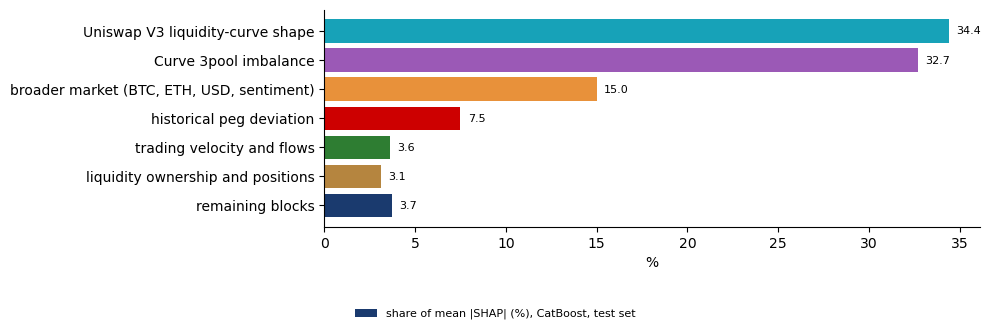

In [5]:
groups = {'Uniswap V3 liquidity-curve shape': 34.4, 'Curve 3pool imbalance': 32.7, 'broader market (BTC, ETH, USD, sentiment)': 15.0,
          'historical peg deviation': 7.5, 'trading velocity and flows': 3.6, 'liquidity ownership and positions': 3.1}
groups['remaining blocks'] = round(100 - sum(groups.values()), 1)
names = list(groups)[::-1]
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.barh(names, [groups[k] for k in names], color=[TEAL, ETH, BTC, RED, GREEN, GOLD, BLUE][::-1],
        label='share of mean |SHAP| (%), CatBoost, test set')
for i, k in enumerate(names):
    ax.text(groups[k] + 0.4, i, f'{groups[k]:.1f}', va='center', fontsize=8)
ax.set_xlabel('%')
save(fig, 'ba_l4_paper_shap', 0.12, ncol=1)

## Key numbers

In [6]:
pd.Series(groups, name='share of mean |SHAP| (%)').to_frame()

,share of mean |SHAP| (%)
Uniswap V3 liquidity-curve shape,34.4
Curve 3pool imbalance,32.7
"broader market (BTC, ETH, USD, sentiment)",15.0
historical peg deviation,7.5
trading velocity and flows,3.6
liquidity ownership and positions,3.1
remaining blocks,3.7


**How to read it:** past peg deviations explain only 7.5% of the attribution; the model warns from the liquidity-curve shape (34.4%) and the 3pool imbalance (32.7%), not from the price itself.
This is attribution, not causality: correlated on-chain features share the credit.